In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
import scipy.odr as odr

# Kennlinien

## Diode in Durchlassrichtung 

In [75]:
# Werte einlesen 1 V = 1000 mV
U_diode = np.array([0.31, 0.58, 0.63, 0.66, 0.71]) # in Volt
mI_diode = np.array([0.01, 1.24, 5.06, 10.02, 41.06]) # in Milliampere

In [76]:
# Unsicherheiten

# Unsicherheit der Spannung setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_U_ablese_diode = 0.01/(2*np.sqrt(3)) # Rechtecksverteilung
u_U_mess_diode = U_diode*0.005 + 0.008

u_U_diode = np.sqrt(u_U_ablese_diode**2 + u_U_mess_diode**2)

# Unsicherheit der Stromstärke setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_mI_ablese_diode = 0.01/(2*np.sqrt(3)) # Rechtecksverteilung
u_mI_mess_diode = mI_diode*0.01 + 0.03 

u_mI_diode = np.sqrt(u_mI_ablese_diode**2 + u_mI_mess_diode**2)

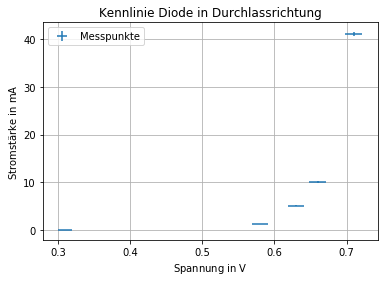

In [77]:
#Plot

plt.errorbar(U_diode, mI_diode, xerr = u_U_diode, yerr = u_mI_diode, label="Messpunkte", marker = "", linestyle = "", zorder = 2)
#plt.plot(U_diode, mI_diode, color = "lightblue", zorder = 1)
plt.grid()
plt.xlabel("Spannung in $\mathrm{V}$")
plt.ylabel("Stromstärke in $\mathrm{mA}$")
plt.legend()
plt.title("Kennlinie Diode in Durchlassrichtung")
plt.savefig('Kennlinie Diode in Durchlassrichtung.pdf')

## Zenerdiode

### Durchlassrichtung

In [78]:
# Werte einlesen
U_zener_durch = np.array([0.001, 0.532, 0.626, 0.64, 0.659, 0.671, 0.681, 0.691, 0.701, 0.706, 0.71])
mI_zener_durch = np.array([0.01, 0.07, 1.54, 2.6, 5.17, 8.18, 12.11, 17.45, 25.51, 31.47, 37.1]) # in Milliampere

In [79]:
# Unsicherheiten

# Unsicherheit der Spannung setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_U_ablese_zener_durch = 0.001/(2*np.sqrt(3)) # Rechtecksverteilung
u_U_mess_zener_durch = U_zener_durch*0.0005 + 0.008 

u_U_zener_durch = np.sqrt(u_U_ablese_zener_durch**2 + u_U_mess_zener_durch**2)

# Unsicherheit der Stromstärke setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_mI_ablese_zener_durch = 0.01/(2*np.sqrt(3)) # Rechtecksverteilung
u_mI_mess_zener_durch = mI_zener_durch*0.01 + 0.03

u_mI_zener_durch = np.sqrt(u_mI_ablese_zener_durch**2 + u_mI_mess_zener_durch**2)

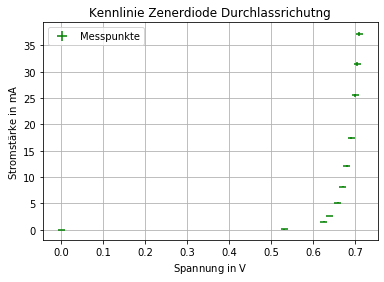

In [80]:
#Plot

plt.errorbar(U_zener_durch, mI_zener_durch, xerr = u_U_zener_durch, yerr = u_mI_zener_durch, color = "green", label="Messpunkte", marker = "", linestyle = "", zorder = 2)
#plt.plot(U_zener_durch, mI_zener_durch, color = "lightgreen", zorder = 1)
plt.grid()
plt.legend()
plt.xlabel("Spannung in $\mathrm{V}$")
plt.ylabel("Stromstärke in $\mathrm{mA}$")
plt.title("Kennlinie Zenerdiode Durchlassrichutng")
plt.savefig('Kennlinie Zenerdiode Durchlassrichutng.pdf')

### Sperrrichtung 

In [3]:
# Werte einlesen
U_zener_sperr = np.array([0.46, 2.24, 2.9, 3, 3.34, 3.64, 3.96, 4.07, 4.28, 4.39, 4.51, 4.62, 4.71, 4.79, 4.83, 4.86])*(-1)
mI_zener_sperr = np.array([0.01, 0.01, 0.07, 0.1, 0.29, 0.73, 1.8, 2.45, 4.46, 6.11, 8.88, 12.69, 16.74, 22.57, 26.16, 29.68])*(-1) # in Milliampere

In [4]:
# Unsicherheiten

# Unsicherheit der Spannung setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_U_ablese_zener_sperr = 0.01/(2*np.sqrt(3)) # Rechtecksverteilung
u_U_mess_zener_sperr = U_zener_sperr*0.005 + 0.008 

u_U_zener_sperr = np.sqrt(u_U_ablese_zener_sperr**2 + u_U_mess_zener_sperr**2)

# Unsicherheit der Stromstärke setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_mI_ablese_zener_sperr = 0.01/(2*np.sqrt(3)) # Rechtecksverteilung
u_mI_mess_zener_sperr = mI_zener_sperr*0.01 + 0.03

u_mI_zener_sperr = np.sqrt(u_mI_ablese_zener_sperr**2 + u_mI_mess_zener_sperr**2)

In [9]:
array1 = u_U_zener_sperr/U_zener_sperr
array1.max()
array2 = u_mI_mess_zener_sperr/mI_zener_sperr
array2.max()

0.008989218328840972

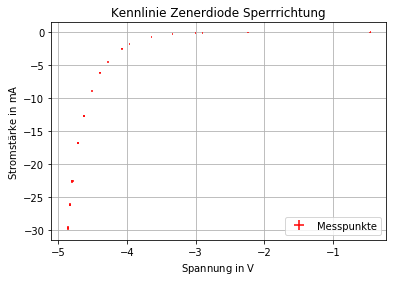

In [83]:
#Plot

plt.errorbar(U_zener_sperr, mI_zener_sperr, xerr = u_U_zener_sperr, yerr = u_mI_zener_sperr, label="Messpunkte", color = "red", marker = "", linestyle = "", zorder = 2)
#plt.plot(U_zener_sperr, mI_zener_sperr, color = "coral", zorder = 1)
plt.grid()
plt.legend()
plt.xlabel("Spannung in $\mathrm{V}$")
plt.ylabel("Stromstärke in $\mathrm{mA}$")
plt.title("Kennlinie Zenerdiode Sperrrichtung")
plt.savefig('Kennlinie Zenerdiode Sperrrichtung.pdf')

## Glühlampe

In [13]:
# Werte einlesen
U_glüh = np.array([0.032, 0.21, 0.312 , 0.47, 0.554, 0.854, 0.951, 1.11, 1.32, 1.77, 2.28, 2.55, 3.07, 3.38, 4.88, 6.65, 6.71])
mI_glüh = np.array([1.26, 5.65, 7.07, 8.82, 9.7, 12.22, 13.02, 14.24, 15.57, 18.66, 21.62, 23.14, 25.86, 27.31, 34, 41.06, 41.33]) # in Milliampere 
R_glüh = U_glüh/(mI_glüh*1e-03)

In [14]:
# Unsicherheiten

# Unsicherheit der Spannung setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_U_ablese_glüh = 0.01/(2*np.sqrt(3)) # Rechtecksverteilung
u_U_mess_glüh = U_glüh*0.005 + 0.008

u_U_glüh = np.sqrt(u_U_ablese_glüh**2 + u_U_mess_glüh**2)

# Unsicherheit der Stromstärke setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_mI_ablese_glüh = 0.01/(2*np.sqrt(3)) # Rechtecksverteilung
u_mI_mess_glüh = mI_glüh*0.01 + 0.03
u_mI_glüh = np.sqrt(u_mI_ablese_glüh**2 + u_mI_mess_glüh**2)

### Fehlerfortpflanzung für den Widerstand R

$R = \frac{U}{I}$

$$
u_R = \sqrt{\left(\frac{1}{I} \cdot u_U \right)^2 + \left(-\frac{U}{I^2} \cdot u_I \right)^2}
$$

In [15]:
def calc_u_R(U_glüh = U_glüh, mI_glüh = mI_glüh, u_U_glüh = u_U_glüh, u_mI_glüh = u_mI_glüh):
    temp1 = (u_U_glüh/(mI_glüh*1e-03))**2
    temp2 = ((U_glüh* u_mI_glüh*1e-03)/ (mI_glüh*1e-03)**2)**2
    return np.sqrt(temp1 + temp2)

In [16]:
u_R_glüh = calc_u_R()
u_R_glüh

array([6.92320226, 1.77507084, 1.54614062, 1.41224681, 1.37142566,
       1.34978271, 1.34789221, 1.35549953, 1.39150856, 1.43243781,
       1.50512346, 1.53932352, 1.60724969, 1.65209183, 1.83169418,
       2.0086546 , 2.01197126])

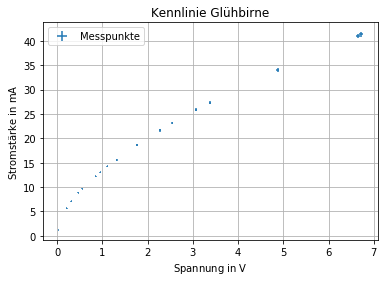

In [88]:
#Plot 1

plt.errorbar(U_glüh, mI_glüh, xerr = u_U_glüh, yerr = u_mI_glüh, label="Messpunkte", marker = "", linestyle = "", zorder = 2)
#plt.plot(U_glüh, mI_glüh, color = "lightblue", zorder = 1)
plt.grid()
plt.xlabel("Spannung in $\mathrm{V}$")
plt.ylabel("Stromstärke in $\mathrm{mA}$")
plt.title("Kennlinie Glühbirne")
plt.legend()
plt.savefig('Kennlinie Glühbirne.pdf')

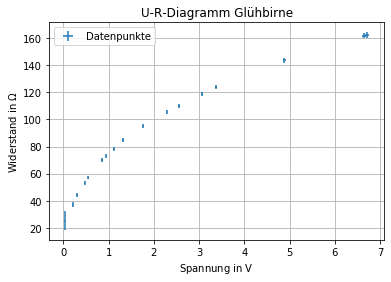

In [89]:
#Plot 2
%matplotlib inline
plt.errorbar(U_glüh, R_glüh, xerr = u_U_glüh, yerr = u_R_glüh, label="Datenpunkte", marker = "", linestyle = "", zorder = 2)
#plt.plot(U_glüh, R_glüh, color = "lightblue", zorder = 1)
plt.grid()
plt.xlabel("Spannung in $\mathrm{V}$")
plt.ylabel("Widerstand in $\Omega$")
plt.title("U-R-Diagramm Glühbirne")
plt.legend()
plt.savefig('U-R-Diagramm Glühbirne.pdf')

### Ermitteln des Winderstandes bei Raumtemp

Das weitere vorgehen liegt der Annahme zur grunde, dass der Draht der Glühlampe beim einschalten des Stroms Raumtemperatur hat. Dann kann man aus dem ersten Messwert den Widerstand der Glühlampe entnehmen. 
Fehlerquelle hierbei: Der Draht wir auch schon bei der ersten Messung 

Beta: [66.82238304 23.22516469]
Beta Std Error: [0.55433812 0.12080045]
Beta Covariance: [[111211.18444649 -20536.99821784]
 [-20536.99821784   5281.24228801]]
Residual Variance: 2.7631281033626477e-06
Inverse Condition #: 5.0304466789245215e-06
Reason(s) for Halting:
  Sum of squares convergence


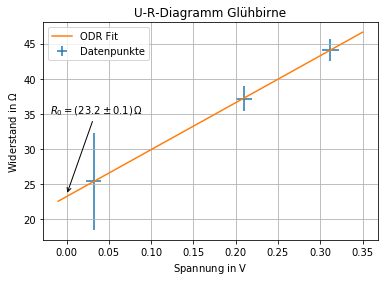

In [43]:
# Extrapolieren einer Geraden durch die ersten drei Punkte
n_U_glüh = U_glüh[:3]
n_R_glüh = R_glüh[:3]
n_u_U_glüh = u_U_glüh[:3]
n_u_R_glüh = u_R_glüh[:3]

mymodel1 = odr.Model(gerade)

mydata1 = odr.RealData(n_U_glüh, n_R_glüh)

myodr1 = odr.ODR(mydata1, mymodel1, beta0=[0.001, 23])

myoutput1 = myodr1.run()

myoutput1.pprint()

werte =np.linspace(-0.01, 0.35, 5)

plt.errorbar(n_U_glüh, n_R_glüh, xerr = n_u_U_glüh, yerr = n_u_R_glüh, label="Datenpunkte",marker = "", linestyle = "", zorder = 1)
plt.plot(werte, gerade(myoutput1.beta, werte), zorder = 2, label = "ODR Fit")
plt.grid()
plt.xlabel("Spannung in $\mathrm{V}$")
plt.ylabel("Widerstand in $\Omega$")
plt.title("U-R-Diagramm Glühbirne")
plt.annotate("$R_0 = (23.2 \pm 0.1) \,\mathrm{\Omega}$", xy=(0, 23.5), xytext=(-0.02, 35), arrowprops=dict(arrowstyle="->"));
plt.legend()
plt.savefig('U-R-Diagramm Glühbirne extrapoliert.pdf')


## NTC-Widerstand


In [90]:
# Werte einlesen

In [91]:
U_ntc = np.array([1.06, 1.96, 3.1, 3.99, 5.01, 6.01, 7.03, 7.98, 7.94])
mI_ntc = np.array([1.47, 2.78, 4.55, 6.13, 8.32, 11.21, 15.91, 41.07, 41.28])

In [92]:
# Unsicherheiten

# Unsicherheit der Spannung setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_U_ablese_ntc = 0.01/(2*np.sqrt(3)) # Rechtecksverteilung
u_U_mess_ntc = U_ntc*0.005 + 0.008

u_U_ntc = np.sqrt(u_U_ablese_ntc**2 + U_ntc*u_U_mess_ntc**2)

# Unsicherheit der Stromstärke setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_mI_ablese_ntc = 0.01/(2*np.sqrt(3)) # Rechtecksverteilung
u_mI_mess_ntc = mI_ntc*0.01 + 0.03
u_mI_ntc = np.sqrt(u_mI_ablese_ntc**2 + u_mI_mess_ntc**2)

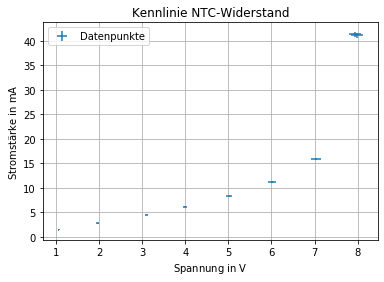

In [93]:
plt.errorbar(U_ntc, mI_ntc, xerr = u_U_ntc, yerr = u_mI_ntc, label="Datenpunkte", marker = "", linestyle = "", zorder = 2)
#plt.plot(U_ntc, mI_ntc, color= "lightblue", zorder = 1)
plt.grid()
plt.xlabel("Spannung in $\mathrm{V}$")
plt.ylabel("Stromstärke in $\mathrm{mA}$")
plt.title("Kennlinie NTC-Widerstand")
plt.legend()
plt.savefig('Kennlinie NTC-Widerstand.pdf')

## Glimmlampe

### Zündspannung

In [2]:
U_glimm_zünd = np.array([15.6, 16.1, 21.1, 30.6, 35.5, 61.3, 86.9, 96.4, 103.7, 106.2, 108.4, 111.2, 86.3, 85, 85, 85, 85, 85.2, 85.4, 85.5, 86.7, 86.9, 87.1, 87.8])
mI_glimm_zünd = np.array([0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.03, 0.03, 0.03, 0.03, 0.03, 0.51, 3, 1.4, 1.05, 0.84, 0.63, 0.41, 0.39, 0.37, 0.35, 0.31, 0.3, 0.3])
# falsch gemessen, sys. Fehler
# Entladung bei 108.4

In [11]:
# Unsicherheiten

# Unsicherheit der Spannung setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_U_ablese_glimm_zünd = 0.1/(2*np.sqrt(3)) #Rechteck
u_U_mess_glimm_zünd = U_glimm_zünd*0.005 + 0.8 

u_U_glimm_zünd = np.sqrt(u_U_ablese_glimm_zünd**2 + u_U_mess_glimm_zünd**2)

# Unsicherheit der Stromstärke setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_mI_ablese_glimm_zünd = 0.01/(2*np.sqrt(3)) #Rechteck
u_mI_mess_glimm_zünd = mI_glimm_zünd*0.01 + 0.03

u_mI_glimm_zünd = np.sqrt(u_mI_ablese_glimm_zünd**2 + u_mI_mess_glimm_zünd**2)
print(u_mI_glimm_zünd[1])

0.03053675381132273


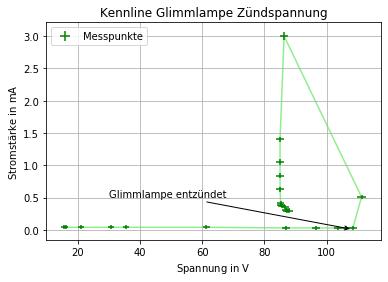

In [10]:
#Plot

plt.errorbar(U_glimm_zünd, mI_glimm_zünd, xerr = u_U_glimm_zünd, yerr = u_mI_glimm_zünd, color = "green",label="Messpunkte", marker = "", linestyle = "", zorder = 2)
plt.plot(U_glimm_zünd, mI_glimm_zünd, color = "lightgreen", zorder = 1)
plt.grid()
plt.xlabel("Spannung in $\mathrm{V}$")
plt.ylabel("Stromstärke in $\mathrm{mA}$")
plt.title("Kennline Glimmlampe Zündspannung")
plt.annotate("Glimmlampe entzündet", xy=(108, 0.01), xytext=(30, 0.5), arrowprops=dict(arrowstyle="->"));
plt.legend()
plt.savefig('Kennlinie Glimmlampe Zündspannung.pdf')

- Verbinden der Messpunkte ergibt physikalisch keinen Sinn
- wurde hier nur getan um den Verlauf aufzu zeigen, da dieser nicht aus den der bloßen Darstellung der Messpunkte heraus geht
- nur eine Betrachtung der Spannung hier sinn voll

### Löschspannung

In [12]:
U_glimm_lösch = np.array([85.6, 85.5, 83.5, 83.9, 77.2, 67.6, 57.1, 46.8, 43.3])
mI_glimm_lösch = np.array([0.27, 0.26, 0.31, 0.3, 0.19, 0.16, 0.13, 0.11, 0.1])
# erlischt bei 83.9

In [14]:
# Unsicherheiten

# Unsicherheit der Spannung setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_U_ablese_glimm_lösch = 0.1/(2*np.sqrt(3)) #Rechteck
u_U_mess_glimm_lösch = U_glimm_lösch*0.005 + 0.8 

u_U_glimm_lösch = np.sqrt(u_U_ablese_glimm_lösch**2 + u_U_mess_glimm_lösch**2)

# Unsicherheit der Stromstärke setzt sich zusammen aus der Ableseunsicherheit und der Ungeauigkeit des Messgerätes 
u_mI_ablese_glimm_lösch = 0.01/(2*np.sqrt(3)) #Rechteck
u_mI_mess_glimm_lösch = mI_glimm_lösch*0.01 + 0.03

u_mI_glimm_lösch = np.sqrt(u_mI_ablese_glimm_lösch**2 + u_mI_mess_glimm_lösch**2)
print(u_mI_glimm_lösch[3])

0.03312602199681292


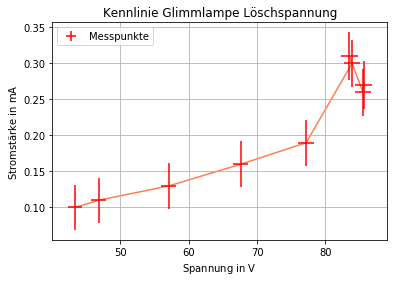

In [99]:
#Plot

plt.errorbar(U_glimm_lösch, mI_glimm_lösch, xerr = u_U_glimm_lösch, yerr = u_mI_glimm_lösch, label="Messpunkte", color = "red", marker = "", linestyle = "", zorder = 2)
plt.plot(U_glimm_lösch, mI_glimm_lösch, color = "coral", zorder = 1)
plt.grid()
plt.title("Kennlinie Glimmlampe Löschspannung")
plt.xlabel("Spannung in $\mathrm{V}$")
plt.ylabel("Stromstärke in $\mathrm{mA}$")
plt.title("Kennlinie Glimmlampe Löschspannung")
plt.legend(loc = 'upper left')
plt.savefig('Kennlinie Glimmlampe Löschspannung.pdf')

## Metalldraht

#### Gesucht bzw. gemessen Widerstand des Metalldrahtes und mittlerer Temperaturkoeffizient
Für den spezifischen Widerstand (zwischen 0°C und 100°C) gilt $\rho = \rho_0 [1 + \alpha (T- T_0)]$(2). Wobei \rho_0 der spez. elek. Widerstand bei $T_0 = 0°C$ oder $20°C$ ist.
Für den mittleren Temperaturkoeffizient gilt: $ \alpha = \frac{1}{\rho_0}\frac{\Delta \rho}{\Delta T} $

Den mittleren Temperaturkoeffizienten kann man bestimmen, indem man T-R-Diagramm plottet und den y-Achsenabschnitt abliest, dies ist nämlich $\alpha$

#### Unsicherheiten
Man ließt die Temperatur ab und den zugehörigen Widerstand.  

In [17]:
# Werte einlesen
T_hoch_metall = np.array([1.9, 4, 4.4, 6, 6.6, 7.6, 10.6, 15.9, 21.6, 40, 42, 46.3, 50.9, 56.7, 60, 64, 69.6, 79.2, 92.8]) # in °C
L_1_hoch_metall = np.array([34.4, 34.4, 34.4, 34.6, 34.7, 35, 35.4, 36, 36.4, 37.55, 37.8, 38.1, 38.5, 39, 39.4, 39.5, 40, 40.7, 41.4])*1e-02 # in m

T_runter_metall = np.array([78.5, 70.8, 65.3, 61.3, 60.4, 54.2, 51.4, 49.7, 47.3, 46.7, 45.1, 44.7, 44.4]) # in °C
L_1_runter_metall = np.array([40.7, 40.3, 40, 39.7, 39.4, 39, 38.7, 38.5, 38.3, 38.2, 38.1, 38, 37.9])*1e-02 # in m


T_metall = np.array([1.9, 4, 4.4, 6, 6.6, 7.6, 10.6, 15.9, 21.6, 40, 42, 46.3, 50.9, 56.7, 60, 64, 69.6, 79.2, 92.8, 78.5, 70.8, 65.3, 61.3, 60.4, 54.2, 51.4, 49.7, 47.3, 46.7, 45.1, 44.7, 44.4])
L_1_metall = np.array([34.4, 34.4, 34.4, 34.6, 34.7, 35, 35.4, 36, 36.4, 37.55, 37.8, 38.1, 38.5, 39, 39.4, 39.5, 40, 40.7, 41.4, 40.7, 40.3, 40, 39.7, 39.4, 39, 38.7, 38.5, 38.3, 38.2, 38.1, 38, 37.9])*1e-02
R_V = 5.1 # in Ohm
l = 1 # in Meter

### Unsicherheit Draht

$$
R_x (T) = \frac{l_1}{l - l_1} R_V   
$$
$l_1$, $l_2$ und $R_V$ sind fehlerbehaftet
$$
u_{R_x} = \sqrt{\left(\frac{l_1}{l - l_1} \cdot u_{R_V}  \right)^2 + \left(\frac{l R_V }{(l - l_1)^2}  \cdot u_{l_1} \right)^2 + \left(-\frac{l_1 R_V}{(l - l_1)^2}  \cdot u_{l} \right)^2}
$$

In [18]:
def calc_R_x(l_1, l = l, R_V = R_V):
    temp = ((l_1*R_V)/(l - l_1))
    return temp

In [19]:
# Unsicherheiten

# Länge
u_l_1 = 0.001/(2*np.sqrt(6)) # Dreieck
u_l = 0.001/(2*np.sqrt(6)) # Dreieck

# Temperatur
u_T_ablese = 0.1/(2*np.sqrt(3)) # Rechteck
u_T_mess_hoch = T_hoch_metall* 0.05
u_T_metall_hoch = np.sqrt(u_T_ablese**2 + u_T_mess_hoch**2)

u_T_mess_runter = T_runter_metall* 0.05
u_T_metall_runter = np.sqrt(u_T_ablese**2 + u_T_mess_runter**2)



# Widerstand 
u_R_V_mess = 5.1*0.009 + 0.1# Hersteller ± (0,9% + 1)
u_R_V_ablese = 0.1/(2*np.sqrt(3)) # Rechteck
u_R_V = np.sqrt(u_R_V_ablese**2 + u_R_V_mess**2)
print(u_R_V)

0.1487284214040253


In [20]:
def calc_u_R_x(l_1, l=l, u_l_1 = u_l_1, u_l = u_l ,R_V = R_V, u_R_V = u_R_V):
    temp1 = ((l_1 * u_R_V) / (l - l_1))**2
    temp2 = ((l * R_V * u_l_1) / ((l - l_1)**2))**2
    temp3 = ((l_1 * R_V * u_l)/ ((l - l_1)**2))**2 
    return np.sqrt(temp1 + temp2 + temp3)

In [21]:
# R_x
R_x_hoch = calc_R_x(L_1_hoch_metall)
R_x_runter = calc_R_x(L_1_runter_metall)
u_R_x_hoch = calc_u_R_x(L_1_hoch_metall)
u_R_x_runter = calc_u_R_x(L_1_runter_metall)
R_x_metall = calc_R_x(L_1_metall)
u_R_x_metall = calc_u_R_x(L_1_metall)

### Fitten 

In [22]:
def gerade(p, x):
    m, c = p
    return m*x + c

In [23]:
mymodel = odr.Model(gerade)

mydata = odr.RealData(T_metall, R_x_metall)

myodr = odr.ODR(mydata, mymodel, beta0=[0.04, 2.5])

myoutput = myodr.run()

myoutput.pprint()

Beta: [0.01077815 2.65513495]
Beta Std Error: [0.0001587  0.00798775]
Beta Covariance: [[ 5.04575002e-05 -2.20735811e-03]
 [-2.20735811e-03  1.27818657e-01]]
Residual Variance: 0.0004991766267374901
Inverse Condition #: 0.24957984352318002
Reason(s) for Halting:
  Sum of squares convergence


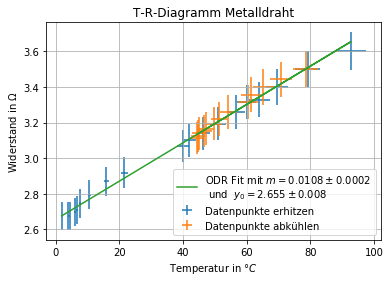

In [33]:
plt.errorbar(T_hoch_metall, R_x_hoch, xerr = u_T_metall_hoch, yerr = u_R_x_hoch, label="Datenpunkte erhitzen",marker = "", linestyle = "", zorder = 1)
plt.errorbar(T_runter_metall, R_x_runter, xerr = u_T_metall_runter, yerr = u_R_x_runter, label="Datenpunkte abkühlen",marker = "", linestyle = "", zorder = 1)
plt.grid()
plt.plot(T_metall, gerade(myoutput.beta, T_metall), label="ODR Fit mit $m = 0.0108 \pm 0.0002$ \n und  $y_0 = 2.655 \pm 0.008$", zorder = 2)
plt.xlabel("Temperatur in $°C$")
plt.ylabel("Widerstand in $\Omega$")
plt.title("T-R-Diagramm Metalldraht")
plt.legend(loc = 'lower right')
plt.savefig('T-R-Diagramm Metalldraht.pdf')

In [108]:
m = myoutput.beta[0]
u_m = myoutput.sd_beta[0]
R_0 = myoutput.beta[1] 
u_R_0 = myoutput.sd_beta[1]
print(m)
print(u_m)
print(R_0)
print(u_R_0)

0.010778150557369604
0.00015870477224182674
2.6551349545974823
0.007987745977449844


### Berechnung alpha
Aus dem Fit kann man sich $\frac{\Delta T}{\Delta R}$ und $R_0$ ausgeben lassen ink. Unsicherheit. Nach Formel XYZ muss man nun $\alpha = \frac{1}{R_0}\frac{\Delta T}{\Delta R}$ rechnen  

### Unsicherheit 
$\frac{\Delta T}{\Delta R}$ und $R_0$ unsicherheitsbelastet.
$$
u_\alpha = \sqrt{\left(\frac{1}{R_0} \cdot u_m \right)^2 + \left(-\frac{1}{R_0 ^2} \frac{\Delta T}{\Delta R}  \cdot u_{R_0} \right)^2}
$$

In [109]:
alpha = m/R_0
u_alpha = np.sqrt((u_m/R_0)**2 + ((m*u_R_0)/(R_0**2))**2)
print(alpha)
print(u_alpha)

0.0040593607261682745
6.100756403534109e-05
